# RUL prediction with an LSTM

The classes live in `src/base.py` (abstract contracts) and `src/models.py` (concrete classes), so the Streamlit app can import the exact same code this notebook uses.

- **Abstraction:** `BaseRULModel` and `BaseRULPreprocessor` define the contract.
- **Encapsulation:** private state (`_pipeline`, `_seq_length`, and the name mangled `__history`) exposed through properties.
- **Inheritance:** `SequencePreprocessor` extends `BaseRULPreprocessor`, `LSTMRULModel` extends `BaseRULModel`, the sklearn transformers extend `BaseEstimator`.
- **Polymorphism:** `LSTMRULModel` overrides the same steps as `XGBRULModel` with Keras behaviour, and the same `ExperimentRunner` drives both.

In [1]:
import os
import random

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from src.handle_data import CMAPSSDataLoader
from src.base import ExperimentRunner
from src.models import SequencePreprocessor, LSTMRULModel

## 1. Reproducibility and small helpers

In [2]:
class SeedManager:
    """Fixes every random seed so runs are reproducible."""

    @staticmethod
    def set_seed(seed=42):
        os.environ["PYTHONHASHSEED"] = "0"
        random.seed(seed)
        np.random.seed(seed)
        tf.random.set_seed(seed)


class DataValidator:
    """Sanity checks for NaN and infinity values."""

    @staticmethod
    def report(**arrays):
        for name, arr in arrays.items():
            arr = np.asarray(arr, dtype=float)
            print(f"{name}: shape={arr.shape}, NaNs={np.isnan(arr).sum()}, infs={np.isinf(arr).sum()}, "
                  f"range=({np.nanmin(arr):.3f}, {np.nanmax(arr):.3f})")


SeedManager.set_seed(42)

## 2. Run the experiment through the abstract interface

In [3]:
loader = CMAPSSDataLoader(subset="FD001")
train_df, test_df, test_last = loader.load()

runner = ExperimentRunner(SequencePreprocessor(rul_cap=125, window=27, seq_length=30),
                          LSTMRULModel(rul_cap=125, seq_length=30, units=64, learning_rate=1e-3))
print(runner)
results = runner.run(train_df, test_df, test_last,
                     validation_split=0.15, epochs=100, batch_size=128)

ExperimentRunner(SequencePreprocessor(rul_cap=125, window=27), LSTMRULModel(name='LSTM', not fitted))


2026-10-24 23:15:36.344647: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-24 23:15:36.344678: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-10-24 23:15:36.344683: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-10-24 23:15:36.344701: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-24 23:15:36.344716: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/100


2026-10-24 23:15:36.830709: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 6559.0264 - mae: 70.1530 - r2_score: -2.7698 - val_loss: 5940.4663 - val_mae: 66.2095 - val_r2_score: -2.3230 - learning_rate: 0.0010
Epoch 2/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 5263.9595 - mae: 61.9831 - r2_score: -2.0255 - val_loss: 4992.9082 - val_mae: 60.2911 - val_r2_score: -1.7929 - learning_rate: 0.0010
Epoch 3/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 4432.6904 - mae: 56.6410 - r2_score: -1.5477 - val_loss: 4241.3164 - val_mae: 55.5331 - val_r2_score: -1.3725 - learning_rate: 0.0010
Epoch 4/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 3777.7729 - mae: 52.3676 - r2_score: -1.1713 - val_loss: 3645.2864 - val_mae: 51.7000 - val_r2_score: -1.0391 - learning_rate: 0.0010
Epoch 5/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 3259.6709 - mae: 48.9129 - r2_score: -0.8735 - val_loss: 3172.9041 - val_mae: 48.6040 - val_r2_score: -0.7749 - learning_rate: 0.0010
Epoch 6/100
118/118 ━━━━━━━━━━━━

In [4]:
d = runner.data
DataValidator.report(X_train_seq=d["X_train"], X_test_seq=d["X_test"], y_train_seq=d["y_train"])

X_train_seq: shape=(17731, 30, 48), NaNs=0, infs=0, range=(0.000, 1.000)
X_test_seq: shape=(100, 30, 48), NaNs=0, infs=0, range=(0.000, 1.490)
y_train_seq: shape=(17731,), NaNs=0, infs=0, range=(0.000, 125.000)


## 3. Evaluation

In [5]:
print(results.round(4))
print(f"NASA score: {runner.nasa_score():.2f}")

             MAE       MSE     RMSE      R2
Training  4.8271   51.4320   7.1716  0.9706
Testing   9.7439  181.9285  13.4881  0.8946
NASA score: 299.75


## 4. Summary and saving (the Streamlit app loads this file)

In [6]:
lstm = runner.model
lstm.summary()
lstm.save("lstm_model.keras")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        28,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 86,981 (339.77 KB)

 Trainable params: 28,993 (113.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 57,988 (226.52 KB)

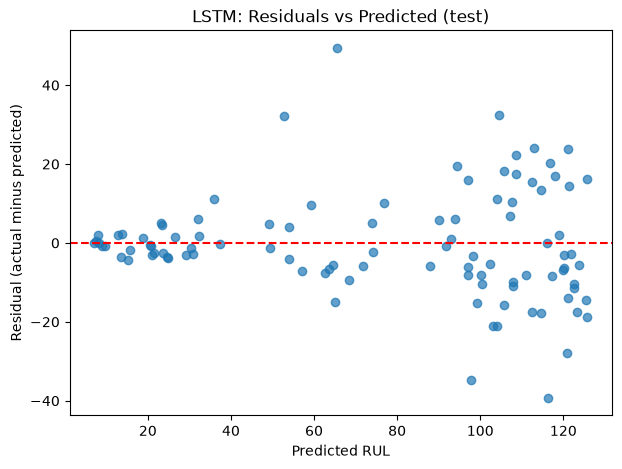

In [7]:
class ResidualPlotter:
    """Residuals versus predicted scatter plot."""

    @staticmethod
    def plot(y_true, y_pred, title="Residuals vs Predicted Values"):
        residual = np.asarray(y_true) - np.asarray(y_pred)
        plt.figure(figsize=(7, 5))
        plt.scatter(y_pred, residual, alpha=0.7)
        plt.axhline(y=0, color="red", linestyle="dashed")
        plt.xlabel("Predicted RUL")
        plt.ylabel("Residual (actual minus predicted)")
        plt.title(title)
        plt.show()


d = runner.data
ResidualPlotter.plot(d["y_test"], d["y_test_pred"], title="LSTM: Residuals vs Predicted (test)")